In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [3]:
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_64_train/',
    labels='inferred',
    label_mode='categorical',
    # label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_64_test/',
    labels='inferred',
    label_mode='categorical',
    # label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    seed=42,
    shuffle=False
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 14057 files belonging to 2 classes.
Using 11246 files for training.
Using 2811 files for validation.
Found 3515 files belonging to 2 classes.


In [4]:
# #Correct model
# model = keras.models.Sequential()
# model.add(keras.Input(shape=(64,64,3)))
# model.add(layers.Conv2D(filters=8,kernel_size=8, 
#                         activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Flatten())
# model.add(layers.Dense(units=32, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))

# model.add(layers.Dense(units=1, activation="sigmoid"))

model = keras.models.Sequential()
model.add(keras.Input(shape=(64,64,3)))
model.add(layers.Conv2D(filters=8, kernel_size=7, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Flatten())

model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dense(units=2, activation='softmax'))


model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.categorical_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=5)

In [5]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    # class_weight= {0: 0.9, 1: 1}
    )

Epoch 1/50
703/703 [==============================] - 22s 23ms/step - loss: 0.5264 - categorical_accuracy: 0.7664 - val_loss: 0.2886 - val_categorical_accuracy: 0.8926
Epoch 2/50
703/703 [==============================] - 8s 11ms/step - loss: 0.2488 - categorical_accuracy: 0.8989 - val_loss: 0.2183 - val_categorical_accuracy: 0.9128
Epoch 3/50
703/703 [==============================] - 8s 11ms/step - loss: 0.2096 - categorical_accuracy: 0.9183 - val_loss: 0.2114 - val_categorical_accuracy: 0.9264
Epoch 4/50
703/703 [==============================] - 8s 11ms/step - loss: 0.1944 - categorical_accuracy: 0.9223 - val_loss: 0.2002 - val_categorical_accuracy: 0.9253
Epoch 5/50
703/703 [==============================] - 8s 11ms/step - loss: 0.1798 - categorical_accuracy: 0.9283 - val_loss: 0.2076 - val_categorical_accuracy: 0.9235
Epoch 6/50
703/703 [==============================] - 8s 11ms/step - loss: 0.1679 - categorical_accuracy: 0.9341 - val_loss: 0.2107 - val_categorical_accuracy: 0.92

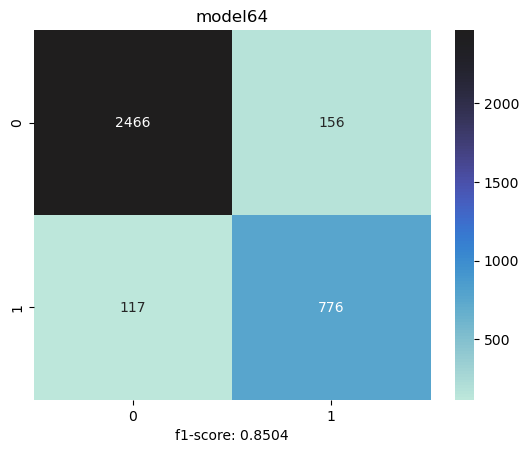

In [6]:
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model64.png')
plt.show()

In [7]:
model.save("./trained_models/model64")

INFO:tensorflow:Assets written to: ./trained_models/model64\assets


INFO:tensorflow:Assets written to: ./trained_models/model64\assets


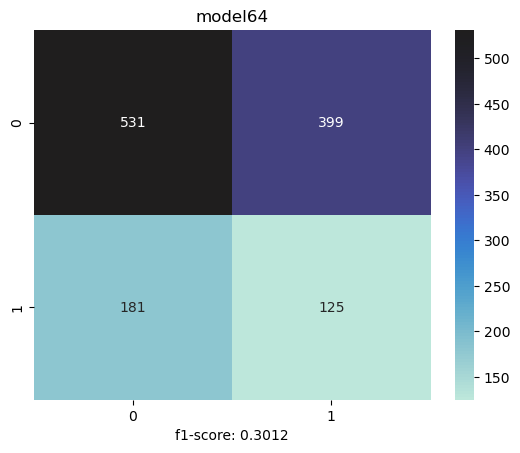

In [5]:
saved_model64 = keras.models.load_model("./trained_models/model64_test/")
# saved_model64.save("./trained_models/model64_2")
array = test_model(saved_model64, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.show()